# Name That LLM — starter GPU baseline

A small, offline baseline intended to **run end to end first**. Character TF-IDF features feed a two-layer PyTorch classifier trained from scratch. TF-IDF extraction runs on the CPU; the neural network's forward pass, loss, backpropagation, and prediction run on the GPU.

**Before running on Kaggle**
1. Join the competition and accept its rules.
2. Create a competition notebook (or import this notebook), and attach **Name That LLM** under Input.
3. In notebook settings, choose a **GPU** accelerator, such as T4 or P100. This uses one GPU, including on a dual-T4 session.
4. Keep **Internet off**. No pip installs, API keys, external datasets, or pretrained model downloads are needed.
5. Run all cells. The final output is `/kaggle/working/submission.parquet`.
6. Save a version with **Save & Run All**, then submit that notebook version to the competition.

The interactive test file is only a small preview. Kaggle reruns the notebook with the full hidden test set when scoring. Predictions are always generated from the test file loaded during that run.

The official metric is **balanced accuracy** (mean recall across the 18 models). This is a modest baseline, with no promised leaderboard score.

Sources: [competition overview and submission requirements](https://www.kaggle.com/competitions/name-that-llm/overview/description), [PyTorch CUDA](https://docs.pytorch.org/docs/stable/cuda.html), [TF-IDF documentation](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).

## 1. Settings and immediate GPU check

Leave `REQUIRE_GPU = True` on Kaggle. If the check fails, enable a GPU and restart the session. Set it to `False` only for an intentional local CPU debugging run. The defaults prioritize a small memory footprint and a short first experiment.

In [1]:
from pathlib import Path
import gc
import json
import random
import time

import joblib
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import balanced_accuracy_score, classification_report
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.preprocessing import LabelEncoder
from IPython.display import display

SEED = 42
REQUIRE_GPU = True
DATA_DIR = None  # Optional: Path("/your/folder/with/train.csv/and/test.csv")
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("baseline_outputs")

MAX_FEATURES = 60_000
HIDDEN_DIM = 256
BATCH_SIZE = 128
EPOCHS = 12
PATIENCE = 3
LEARNING_RATE = 0.003
WEIGHT_DECAY = 0.001
VALID_SIZE = 0.20

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is unavailable. On Kaggle, choose a GPU in notebook settings "
        "and restart the session. For an intentional CPU test only, set REQUIRE_GPU=False."
    )

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    # Perform actual GPU work before loading any data.
    probe = torch.randn(256, 256, device=device)
    _ = probe @ probe.T
    torch.cuda.synchronize()
    del probe, _
    print("CUDA matrix multiplication: passed")
else:
    print("CPU debugging mode enabled.")

assert BATCH_SIZE >= 1 and EPOCHS >= 1 and PATIENCE >= 1
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


PyTorch: 2.11.0+cu128
Device: cuda:0
GPU: Tesla T4
CUDA matrix multiplication: passed


## 2. Load and check the competition data

The official path is tried first. The older Kaggle mount path and local folders are also supported. Local execution can find the CSVs in this notebook's folder or its parent. No external training data is used.

In [2]:
files = list(Path("/kaggle/input").rglob("ntl_open_pool.parquet"))

print("Files found:", files)

# Load the dataset
pool = pd.read_parquet(files[0])

print(len(pool))
print(pool.model.value_counts())

Files found: [PosixPath('/kaggle/input/datasets/crtproduction/name-that-llm-open-pool/ntl_open_pool.parquet')]
223840
model
gemini-3.8-flash          23190
gemini-3.6-flash          18074
gpt-5.6-luna              17740
gpt-5.6-terra             15300
gpt-5.6-sol               14591
gpt-5.5                   13546
claude-fable-5            12773
claude-sonnet-5           12714
glm-5.3-flash             12214
glm-5.3                   11891
claude-opus-4-8           11875
gpt-6-astra               11633
claude-opus-4-6           10866
gemini-3.1-pro-preview    10178
kimi-k3                    9731
claude-opus-5              9417
qwen3.8-max                4566
gemini-3.7-flash           3541
Name: count, dtype: int64


In [3]:
candidates = [Path(DATA_DIR)] if DATA_DIR is not None else [
    Path("/kaggle/input/competitions/name-that-llm"),
    Path("/kaggle/input/name-that-llm"),
    Path.cwd(),
    Path.cwd().parent,
]
data_dir = next(
    (p for p in candidates if (p / "train.csv").is_file() and (p / "test.csv").is_file()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Could not find train.csv and test.csv together. Attach the competition "
        "data under Input, or set DATA_DIR explicitly. Tried: "
        + ", ".join(map(str, candidates))
    )

train = pd.read_csv(data_dir / "train.csv", dtype={"id": "string"})
test = pd.read_csv(data_dir / "test.csv", dtype={"id": "string"})

pool_aligned = pool.copy()
if 'prompt_id' in train.columns and 'prompt_id' not in pool_aligned.columns and 'prompt_group' in pool_aligned.columns:
    pool_aligned = pool_aligned.rename(columns={'prompt_group': 'prompt_id'})
missing_pool_columns = train.columns.difference(pool_aligned.columns).tolist()
extra_pool_columns = pool_aligned.columns.difference(train.columns).tolist()
print('Pool columns missing from train schema:', missing_pool_columns)
print('Pool columns excluded from training:', extra_pool_columns)
if missing_pool_columns:
    raise ValueError(f'Pool is missing training columns: {missing_pool_columns}')
pool_aligned = pool_aligned.loc[:, train.columns]
train = pd.concat([train, pool_aligned], ignore_index=True)
print('Train:', train.shape, train.columns.tolist())  # print() shows the training table's shape; columns.tolist() converts its column names to a list.
print('Test: ', test.shape, test.columns.tolist())  # print() shows the test table's shape and column-name list.


for frame, required, name in [
    (train, {"id", "text", "model"}, "train"),
    (test, {"id", "text"}, "test"),
]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {sorted(missing)}")
    if frame.empty:
        raise ValueError(f"{name} is empty.")
    if frame["id"].isna().any() or frame["id"].duplicated().any():
        raise ValueError(f"{name} IDs must be non-null and unique.")
    if frame["text"].isna().any() or frame["text"].astype(str).str.strip().eq("").any():
        raise ValueError(f"{name} contains missing or empty text.")
    frame["text"] = frame["text"].astype(str)

VALID_LABELS = {
    "gpt-5.5", "gpt-5.6-luna", "gpt-5.6-sol", "gpt-5.6-terra", "gpt-6-astra",
    "gemini-3.1-pro-preview", "gemini-3.6-flash", "gemini-3.7-flash", "gemini-3.8-flash",
    "claude-fable-5", "claude-opus-4-6", "claude-opus-4-8", "claude-opus-5", "claude-sonnet-5",
    "qwen3.8-max", "glm-5.3", "glm-5.3-flash", "kimi-k3",
}
if train["model"].isna().any() or set(train["model"]) != VALID_LABELS:
    raise ValueError("Training labels do not match the competition's 18 model names.")

encoder = LabelEncoder()
y = encoder.fit_transform(train["model"]).astype(np.int64)
num_classes = len(encoder.classes_)
print("Data folder:", data_dir)
print(f"Training rows: {len(train):,} | Test rows: {len(test):,} | Classes: {num_classes}")
display(train["model"].value_counts().rename_axis("model").to_frame("rows"))

print(train.head(20))


Pool columns missing from train schema: []
Pool columns excluded from training: ['also_in', 'flag_gemini37_routing_risk', 'flag_kb_proxy', 'flag_kb_proxy_after_ruling', 'flag_near_train_prompt', 'flag_train_prompt_regen', 'gen_date', 'gen_reasoning', 'gen_reasoning_evidence', 'gen_reasoning_raw', 'gen_route', 'gen_served_model', 'lab', 'match_weight', 'max_cos_train', 'max_sim_train_prompt', 'n_sources', 'n_words', 'origin_hint', 'panel_labels', 'prompt_canon', 'prompt_evidence', 'source_dataset', 'source_file', 'source_license', 'style_score']
Train: (226539, 4) ['id', 'prompt_id', 'text', 'model']
Test:  (3, 2) ['id', 'text']
Data folder: /kaggle/input/competitions/name-that-llm
Training rows: 226,539 | Test rows: 3 | Classes: 18


,rows
model,
gemini-3.8-flash,23340
gemini-3.6-flash,18224
gpt-5.6-luna,17890
gpt-5.6-terra,15450
gpt-5.6-sol,14741
gpt-5.5,13696
claude-fable-5,12922
claude-sonnet-5,12864
glm-5.3-flash,12364


              id prompt_id                                               text  \
0   0018b3765972      p081  When a language dies, a particular astronomy d...   
1   0041ac86ee93      p073  Data science communities matter because they a...   
2   005a19083eae      p120  In the final twilight of time, the last embers...   
3   009319596f10      p073  Data science communities matter because they t...   
4   00d3e8c92596      p097  Deep inside each ear, three tiny loops of bone...   
5   00f73c3a3937      p065  We navigate the modern world with an unearned ...   
6   010967f56aaf      p090  Beneath a ferocious sky warped by monstrous gr...   
7   010b4f492abc      p036  The Banach-Tarski paradox reveals that a solid...   
8   013e6e0913db      p011  Imagine a finite box expanding into a thousand...   
9   0149bc156d4e      p139  Under stress, the brain treats contradiction a...   
10  014fcc7128fb      p106  Each time an adult wrestles with a new idea, p...   
11  0151ce9f9c9c      p003  

## 3. Hold out prompts for validation

When `prompt_id` is available, all responses to a prompt stay on the same side of the split. This better represents prediction on unseen prompts. Otherwise, use a stratified row split. Only `text` enters the classifier; IDs and prompt IDs are never features.

In [4]:
row_ids = np.arange(len(train))
if "prompt_id" in train.columns:
    if train["prompt_id"].isna().any() or train["prompt_id"].nunique() < 2:
        raise ValueError("prompt_id must contain at least two non-null prompt groups.")
    splitter = GroupShuffleSplit(n_splits=1, test_size=VALID_SIZE, random_state=SEED)
    train_idx, valid_idx = next(splitter.split(row_ids, y, groups=train["prompt_id"]))
    assert set(train.iloc[train_idx]["prompt_id"]).isdisjoint(train.iloc[valid_idx]["prompt_id"])
    print("Validation split: held-out prompt groups")
else:
    train_idx, valid_idx = train_test_split(
        row_ids, test_size=VALID_SIZE, random_state=SEED, stratify=y
    )
    print("Validation split: stratified rows (no prompt_id available)")

if set(y[train_idx]) != set(range(num_classes)) or set(y[valid_idx]) != set(range(num_classes)):
    raise ValueError("The split does not include all classes on both sides. Adjust VALID_SIZE or SEED.")

print(f"Train: {len(train_idx):,} | Validation: {len(valid_idx):,}")

def make_vectorizer():
    return TfidfVectorizer(
        analyzer="char", ngram_range=(3, 5), lowercase=False,
        min_df=2, max_features=MAX_FEATURES, sublinear_tf=True, dtype=np.float32,
    )

start = time.perf_counter()

vectorizer = make_vectorizer()
X_train = vectorizer.fit_transform(
    train.iloc[train_idx]["text"]
)

print(f"TF-IDF fitting: {time.perf_counter() - start:.2f}s")

start = time.perf_counter()

X_valid = vectorizer.transform(
    train.iloc[valid_idx]["text"]
)

print(f"Validation transform: {time.perf_counter() - start:.2f}s")



print("Training feature matrix:", X_train.shape)
print(f"Dense input per full batch: {BATCH_SIZE * X_train.shape[1] * 4 / 1024**2:.1f} MiB")


Validation split: held-out prompt groups
Train: 174,218 | Validation: 52,321
TF-IDF fitting: 231.49s
Validation transform: 70.99s
Training feature matrix: (174218, 60000)
Dense input per full batch: 29.3 MiB


## 4. Define the GPU classifier

The network is TF-IDF → 128 hidden units → model probabilities. Inverse-frequency class weights give rare models more influence during training. Features remain sparse in CPU memory; only one batch is made dense and transferred to the GPU at a time. This avoids densifying the full dataset.

This intentionally uses ordinary float32 PyTorch operations, with no mixed-precision or distributed setup to configure.

In [5]:
class TextClassifier(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, HIDDEN_DIM),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(HIDDEN_DIM, n_classes),
        )

    def forward(self, features):
        return self.layers(features)

def feature_batch(matrix, rows):
    return torch.from_numpy(matrix[rows].toarray()).to(device)

def make_loss(labels):
    counts = np.bincount(labels, minlength=num_classes)
    if (counts == 0).any():
        raise ValueError("At least one class is missing from the training labels.")
    weights = len(labels) / (num_classes * counts)
    return nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))

def train_one_epoch(model, optimizer, criterion, matrix, labels, rng):
    model.train()
    total_loss = 0.0
    order = rng.permutation(len(labels))
    for start in range(0, len(order), BATCH_SIZE):
        rows = order[start:start + BATCH_SIZE]
        features = feature_batch(matrix, rows)
        targets = torch.as_tensor(labels[rows], dtype=torch.long, device=device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(features), targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss; try lowering LEARNING_RATE.")
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(rows)
    return total_loss / len(labels)

@torch.inference_mode()
def predict_classes(model, matrix):
    model.eval()
    predictions = []
    for start in range(0, matrix.shape[0], BATCH_SIZE):
        logits = model(feature_batch(matrix, slice(start, start + BATCH_SIZE)))
        predictions.append(logits.argmax(dim=1).cpu().numpy())
    return np.concatenate(predictions)

model = TextClassifier(X_train.shape[1], num_classes).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion = make_loss(y[train_idx])
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Model device:", next(model.parameters()).device)
assert next(model.parameters()).device.type == device.type


Model parameters: 15,364,882
Model device: cuda:0


## 5. Train and measure balanced accuracy

Keep the best validation epoch and stop after three epochs without improvement. Validation is a diagnostic estimate, not a leaderboard score. The printed loss is a batch-aggregated training diagnostic.

In [6]:
rng = np.random.default_rng(SEED)
history = []
best_score = -1.0
best_epoch = 0
best_state = None
stale_epochs = 0
started = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    loss = train_one_epoch(model, optimizer, criterion, X_train, y[train_idx], rng)
    valid_predictions = predict_classes(model, X_valid)
    score = balanced_accuracy_score(y[valid_idx], valid_predictions)
    history.append({"epoch": epoch, "train_loss": loss, "balanced_accuracy": float(score)})
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss {loss:.4f} | validation balanced accuracy {score:.4f}")
    if score > best_score:
        best_score, best_epoch = float(score), epoch
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print("Early stopping.")
            break

model.load_state_dict(best_state)
valid_predictions = predict_classes(model, X_valid)
print(f"Best epoch: {best_epoch} | Balanced accuracy: {best_score:.4f}")
print(f"Training + validation elapsed: {time.perf_counter() - started:.1f} seconds")
print(classification_report(
    y[valid_idx], valid_predictions, labels=np.arange(num_classes),
    target_names=encoder.classes_, digits=3, zero_division=0,
))
pd.DataFrame(history).to_csv(OUTPUT_DIR / "validation_history.csv", index=False)
if device.type == "cuda":
    print(f"Peak GPU memory allocated: {torch.cuda.max_memory_allocated() / 1024**2:.1f} MiB")

nn_valid_predictions = valid_predictions.copy()


Epoch 01/12 | loss 1.6904 | validation balanced accuracy 0.4310
Epoch 02/12 | loss 1.1136 | validation balanced accuracy 0.4667
Epoch 03/12 | loss 0.7187 | validation balanced accuracy 0.4541
Epoch 04/12 | loss 0.4374 | validation balanced accuracy 0.4524
Epoch 05/12 | loss 0.2642 | validation balanced accuracy 0.4519
Early stopping.
Best epoch: 2 | Balanced accuracy: 0.4667
Training + validation elapsed: 163.1 seconds
                        precision    recall  f1-score   support

        claude-fable-5      0.347     0.334     0.341      3497
       claude-opus-4-6      0.454     0.654     0.536      2115
       claude-opus-4-8      0.387     0.413     0.399      2305
         claude-opus-5      0.450     0.737     0.559      1807
       claude-sonnet-5      0.453     0.617     0.523      2440
gemini-3.1-pro-preview      0.509     0.748     0.606      1998
      gemini-3.6-flash      0.557     0.564     0.560      3542
      gemini-3.7-flash      0.232     0.406     0.295      1959


## Adding logistic regression classifier in an attempt to beat the NN's score

In [7]:
class LogRegTextClassifier(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.linear = nn.Linear(n_features, n_classes)

    def forward(self, features):
        return self.linear(features)

model = LogRegTextClassifier(X_train.shape[1], num_classes).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion = make_loss(y[train_idx])
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Model device:", next(model.parameters()).device)
assert next(model.parameters()).device.type == device.type

Model parameters: 1,080,018
Model device: cuda:0


In [8]:
rng = np.random.default_rng(SEED)
history = []
best_score = -1.0
best_epoch = 0
best_state = None
stale_epochs = 0
started = time.perf_counter()

LOGREG_EPOCHS = 30
LOGREG_PATIENCE = 5

for epoch in range(1, LOGREG_EPOCHS + 1):
    loss = train_one_epoch(model, optimizer, criterion, X_train, y[train_idx], rng)
    valid_predictions = predict_classes(model, X_valid)
    score = balanced_accuracy_score(y[valid_idx], valid_predictions)
    history.append({"epoch": epoch, "train_loss": loss, "balanced_accuracy": float(score)})
    print(f"Epoch {epoch:02d}/{LOGREG_EPOCHS} | loss {loss:.4f} | validation balanced accuracy {score:.4f}")
    if score > best_score:
        best_score, best_epoch = float(score), epoch
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= LOGREG_PATIENCE:
            print("Early stopping.")
            break

model.load_state_dict(best_state)
valid_predictions = predict_classes(model, X_valid)
print(f"Best epoch: {best_epoch} | Balanced accuracy: {best_score:.4f}")
print(f"Training + validation elapsed: {time.perf_counter() - started:.1f} seconds")
print(classification_report(
    y[valid_idx], valid_predictions, labels=np.arange(num_classes),
    target_names=encoder.classes_, digits=3, zero_division=0,
))
pd.DataFrame(history).to_csv(OUTPUT_DIR / "validation_history.csv", index=False)
if device.type == "cuda":
    print(f"Peak GPU memory allocated: {torch.cuda.max_memory_allocated() / 1024**2:.1f} MiB")

logreg_valid_predictions = valid_predictions.copy()


Epoch 01/30 | loss 2.1227 | validation balanced accuracy 0.4294
Epoch 02/30 | loss 1.5302 | validation balanced accuracy 0.4540
Epoch 03/30 | loss 1.3017 | validation balanced accuracy 0.4609
Epoch 04/30 | loss 1.1566 | validation balanced accuracy 0.4646
Epoch 05/30 | loss 1.0506 | validation balanced accuracy 0.4676
Epoch 06/30 | loss 0.9667 | validation balanced accuracy 0.4688
Epoch 07/30 | loss 0.8973 | validation balanced accuracy 0.4681
Epoch 08/30 | loss 0.8392 | validation balanced accuracy 0.4671
Epoch 09/30 | loss 0.7885 | validation balanced accuracy 0.4672
Epoch 10/30 | loss 0.7441 | validation balanced accuracy 0.4672
Epoch 11/30 | loss 0.7043 | validation balanced accuracy 0.4634
Early stopping.
Best epoch: 6 | Balanced accuracy: 0.4688
Training + validation elapsed: 247.7 seconds
                        precision    recall  f1-score   support

        claude-fable-5      0.352     0.310     0.330      3497
       claude-opus-4-6      0.495     0.620     0.551      2115


### Generating Confusion Matrices for Both Classifiers

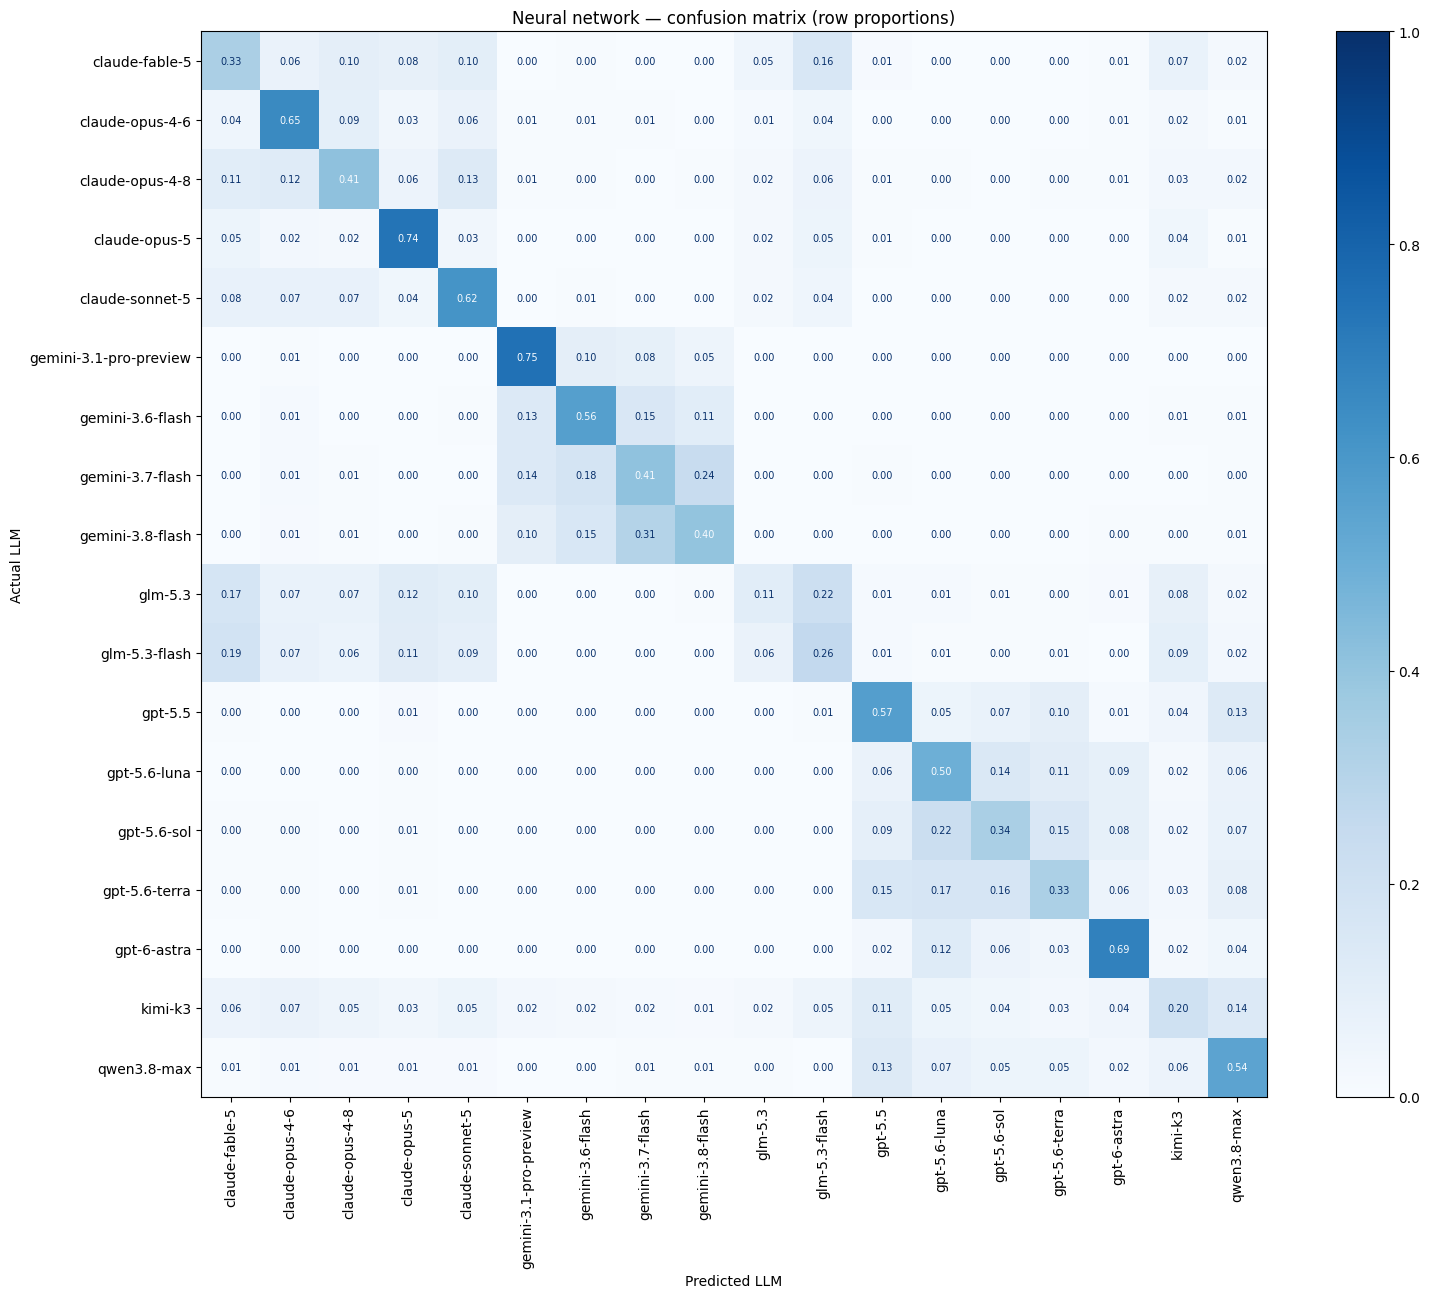

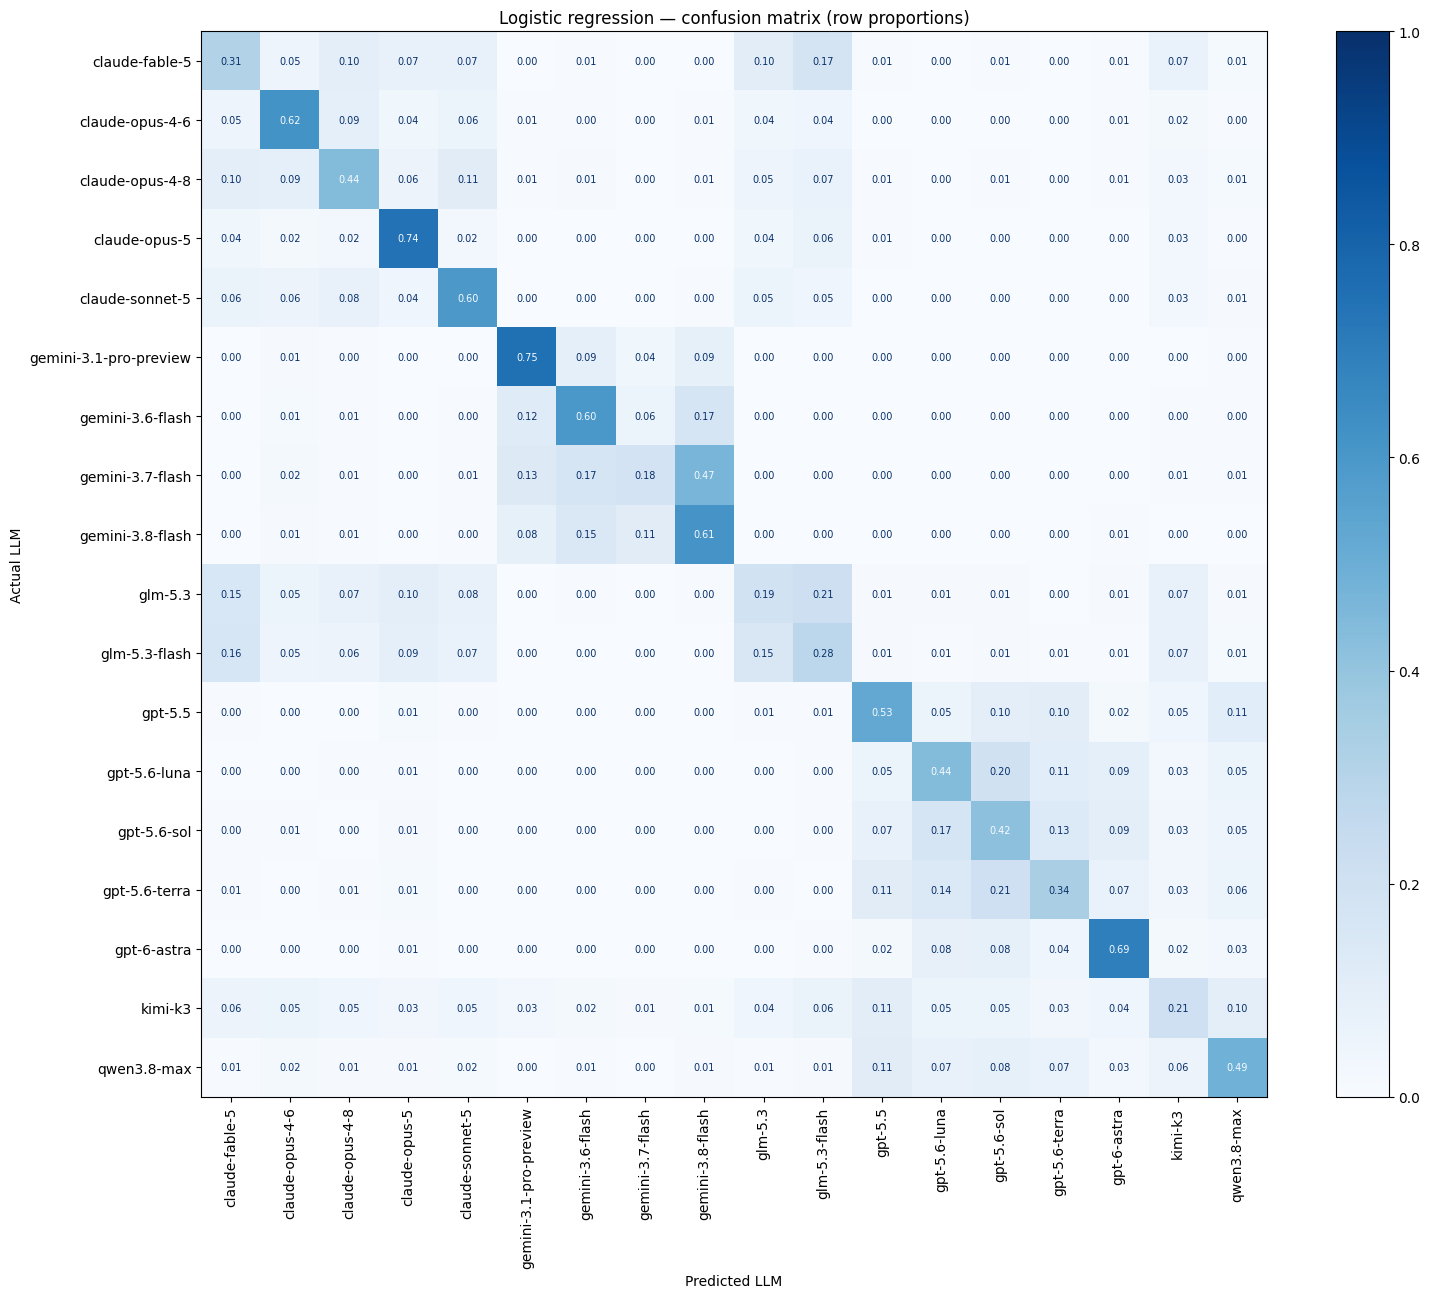

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Both prediction arrays must correspond to these same validation rows,
# in exactly the same order.
y_valid = y[valid_idx]
class_ids = np.arange(num_classes)
class_names = encoder.classes_

def plot_confusion_matrix(predictions, title, filename):
    assert len(predictions) == len(y_valid)

    # Counts: rows = actual classes, columns = predicted classes.
    counts = confusion_matrix(
        y_valid,
        predictions,
        labels=class_ids,
    )

    # Normalise each row to show proportions within each actual class.
    normalised = confusion_matrix(
        y_valid,
        predictions,
        labels=class_ids,
        normalize="true",
    )

    fig, ax = plt.subplots(figsize=(16, 13))

    display = ConfusionMatrixDisplay(
        confusion_matrix=normalised,
        display_labels=class_names,
    )
    display.plot(
        ax=ax,
        cmap="Blues",
        values_format=".2f",
        xticks_rotation=90,
        colorbar=True,
        im_kw={"vmin": 0, "vmax": 1},
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted LLM")
    ax.set_ylabel("Actual LLM")

    for text in display.text_.ravel():
        text.set_fontsize(7)

    fig.tight_layout()
    fig.savefig(
        OUTPUT_DIR / f"{filename}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

    # Save exact counts for inspecting individual mistakes.
    count_table = pd.DataFrame(
        counts,
        index=class_names,
        columns=class_names,
    )
    count_table.index.name = "actual_model"
    count_table.columns.name = "predicted_model"
    count_table.to_csv(OUTPUT_DIR / f"{filename}_counts.csv")


plot_confusion_matrix(
    nn_valid_predictions,
    "Neural network — confusion matrix (row proportions)",
    "neural_network_confusion",
)

plot_confusion_matrix(
    logreg_valid_predictions,
    "Logistic regression — confusion matrix (row proportions)",
    "logreg_confusion",
)

### Combining the Classifications

## 6. Refit on all training rows

Use the selected epoch count to train a fresh model on all labeled data. Refit TF-IDF on all training text at this stage. The held-out score above belongs to the validation model; the final model has no independent score. Test text is transformed only, never used to fit the vocabulary or network.

In [10]:
del model, optimizer, criterion, best_state, X_train, X_valid, vectorizer
gc.collect()
if device.type == "cuda":
    torch.cuda.empty_cache()
seed_everything()
rng = np.random.default_rng(SEED)

vectorizer = make_vectorizer()
X_all = vectorizer.fit_transform(train["text"])
final_model = TextClassifier(X_all.shape[1], num_classes).to(device)
optimizer = torch.optim.AdamW(final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion = make_loss(y)

for epoch in range(1, best_epoch + 1):
    loss = train_one_epoch(final_model, optimizer, criterion, X_all, y, rng)
    print(f"Full-data epoch {epoch:02d}/{best_epoch} | loss {loss:.4f}")

# Save everything needed to reproduce inference without retraining.
joblib.dump(vectorizer, OUTPUT_DIR / "tfidf.joblib")
torch.save({
    "state_dict": {name: value.detach().cpu() for name, value in final_model.state_dict().items()},
    "n_features": X_all.shape[1],
    "hidden_dim": HIDDEN_DIM,
    "classes": encoder.classes_.tolist(),
}, OUTPUT_DIR / "classifier.pt")
metrics = {
    "seed": SEED, "validation_balanced_accuracy": best_score,
    "selected_epoch": best_epoch, "train_rows": len(train),
    "validation_rows": len(valid_idx), "device": str(device),
    "validation_split": "prompt groups" if "prompt_id" in train.columns else "stratified rows",
    "max_features": MAX_FEATURES, "hidden_dim": HIDDEN_DIM, "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY,
}
(OUTPUT_DIR / "run_summary.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")


Full-data epoch 01/6 | loss 1.6333
Full-data epoch 02/6 | loss 1.1005
Full-data epoch 03/6 | loss 0.7474
Full-data epoch 04/6 | loss 0.4797
Full-data epoch 05/6 | loss 0.3093
Full-data epoch 06/6 | loss 0.2179


325

## 7. Predict and write the competition submission

Keep test row order and the original IDs. The required output is **Parquet**, with exactly `id` and `model` columns. Read it back to verify that it was written correctly. A small interactive test submission is expected; the code handles the hidden test set in batches as well.

In [11]:
X_test = vectorizer.transform(test["text"])
predicted_ids = predict_classes(final_model, X_test)
predicted_labels = encoder.inverse_transform(predicted_ids)
submission = pd.DataFrame({"id": test["id"].to_numpy(), "model": predicted_labels})

assert submission.columns.tolist() == ["id", "model"]
assert len(submission) == len(test)
assert not submission.isna().any().any()
assert submission["id"].is_unique
assert submission["id"].tolist() == test["id"].tolist()
assert set(submission["model"]).issubset(VALID_LABELS)

submission_path = OUTPUT_DIR / "submission.parquet"
submission.to_parquet(submission_path, index=False, engine="pyarrow")
saved = pd.read_parquet(submission_path)
pd.testing.assert_frame_equal(saved, submission)
print(f"Saved {len(saved):,} predictions to: {submission_path.resolve()}")
display(saved.head())


Saved 3 predictions to: /kaggle/working/submission.parquet


,id,model
0,00353fb1c541,claude-opus-4-8
1,005f5a9a6139,gpt-5.6-sol
2,0062a53d5487,gemini-3.8-flash


## After the first successful run

- Record the validation balanced accuracy and saved `run_summary.json` as your first baseline.
- If memory is tight, lower `BATCH_SIZE` to 64 or `MAX_FEATURES` to 15,000.
- Change one setting at a time after confirming the default notebook runs.
- This network is small, so GPU utilization may be intermittent while the CPU builds TF-IDF features or prepares batches. The model and its training calculations still run on CUDA.
- A later experiment could fine-tune a pretrained text encoder. That would require attaching its weights and tokenizer as offline inputs.

Other saved outputs: `validation_history.csv`, `tfidf.joblib`, `classifier.pt`, and `run_summary.json`. The only file used for competition predictions is `submission.parquet`.
